# Stage 4: Daily Glucose Pattern (Participant 001)

Stages 2–3 described glucose over the whole recording. Here we look at how it changes **across the 24-hour day**, using the food log to explain what we see.

| # | Question |
|---|---|
| Q1 | What does a "typical day" look like? (Ambulatory Glucose Profile) |
| Q2 | Which hours of the day have the highest and lowest glucose? |
| Q3 | How does overnight glucose (00:00–06:00) compare with daytime? |
| Q4 | Is there an early-morning rise before breakfast (dawn phenomenon)? |
| Q5 | What is the fasting glucose each morning (just before the first meal)? |

## Setup

Settings used throughout:

- `EXCLUDE_FIRST_24H`: Stage 1 found the first 24 h read ~10 mg/dL lower than the rest. Set to `True` to check whether that changes the daily pattern.
- `AGP_BIN_MIN`: width of the time-of-day bins for the AGP plot (15 min).
- `FASTING_WINDOW_MIN`: how far before the first meal we look for the fasting value (30 min).
- `DAY_START_HOUR`: meals before this hour are not counted as "breakfast" (04:00).

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import timedelta

PID = "001"
DATA_DIR = "../../../datasets/big-ideas-glycemic-wearable"
CLEAN_PATH = f"../clean_data/glucose_{PID}_clean.csv"
RAW_PATH = f"{DATA_DIR}/{PID}/Dexcom_{PID}.csv"
FOOD_PATH = f"{DATA_DIR}/{PID}/Food_Log_{PID}.csv"

EXCLUDE_FIRST_24H = False
AGP_BIN_MIN = 15
FASTING_WINDOW_MIN = 30
DAY_START_HOUR = 4

## Load glucose

Same loader as the previous stages: the cleaned Stage 1 file, or the raw Dexcom file as a fallback.

In [2]:
if os.path.exists(CLEAN_PATH):
    glu = pd.read_csv(CLEAN_PATH, parse_dates=["timestamp"])
    print("Loaded cleaned file from Stage 1")
else:
    raw = pd.read_csv(RAW_PATH, skiprows=range(1, 13))
    raw = raw[raw["Event Type"] == "EGV"]
    glu = pd.DataFrame({
        "timestamp": pd.to_datetime(raw["Timestamp (YYYY-MM-DDThh:mm:ss)"]),
        "glucose": pd.to_numeric(raw["Glucose Value (mg/dL)"], errors="coerce"),
    }).dropna().drop_duplicates("timestamp")
    print("Stage 1 file not found, loaded raw Dexcom file instead")

glu = glu.sort_values("timestamp").reset_index(drop=True)

if EXCLUDE_FIRST_24H:
    glu = glu[glu["timestamp"] >= glu["timestamp"].iloc[0] + pd.Timedelta("24h")].reset_index(drop=True)
    print("First 24 h excluded")

glu["date"] = glu["timestamp"].dt.date
glu["hour"] = glu["timestamp"].dt.hour
glu["tod"] = glu["hour"] + glu["timestamp"].dt.minute / 60   # time of day as decimal hours

glu_s = glu.set_index("timestamp")["glucose"]   # time-indexed series for window lookups
print("Readings:", len(glu), "| days:", glu["date"].nunique())

Loaded cleaned file from Stage 1
Readings: 2561 | days: 10


## Load and check the food log

The food log has one row per **food item**, so one meal can span several rows with the same `time_begin`. The columns are `date`, `time`, `time_begin`, `time_end` (empty), `logged_food`, `amount`, `unit`, `searched_food`, `calorie`, `total_carb`, `dietary_fiber`, `sugar`, `protein`, and `total_fat`.

Food logs are typed in by hand, so we look for two kinds of likely mistakes:
- meals logged in the middle of the night (before `DAY_START_HOUR`)
- rows whose time is much earlier than the row before it on the same day (e.g. an AM/PM mix-up)

In [3]:
food = pd.read_csv(FOOD_PATH)
food["time_begin"] = pd.to_datetime(food["time_begin"])
print("Food items:", len(food))
food.head()

Food items: 61


,date,time,time_begin,time_end,logged_food,amount,unit,searched_food,calorie,total_carb,dietary_fiber,sugar,protein,total_fat
0,2020-02-13,18:00:00,2020-02-13 18:00:00,NaN,Berry Smoothie,20.00,fluid ounce,Strawberry Smoothie,456.0,85.0,1.7,83.0,16.0,3.3
1,2020-02-13,20:30:00,2020-02-13 20:30:00,NaN,Chicken Leg,1.00,NaN,chicken leg,475.0,0.0,0.0,0.0,62.0,23.0
2,2020-02-13,20:30:00,2020-02-13 20:30:00,NaN,Asparagus,4.00,NaN,Asparagus,13.0,2.5,1.2,0.8,1.4,0.1
3,2020-02-14,07:10:00,2020-02-14 07:10:00,NaN,Natrel Lactose Free 2 Percent,8.00,fluid ounce,(Natrel) Lactose Free 2% Partly Skimmed Milk,120.0,9.0,NaN,8.0,12.0,NaN
4,2020-02-14,07:10:00,2020-02-14 07:10:00,NaN,Standard Breakfast,0.75,cup,"(Kellogg's) Frosted Flakes, Cereal",110.0,26.0,NaN,10.0,1.0,NaN


In [4]:
# Missing values per column (fiber and fat are often left empty)
food.isna().sum().to_frame("missing").T

,date,time,time_begin,time_end,logged_food,amount,unit,searched_food,calorie,total_carb,dietary_fiber,sugar,protein,total_fat
missing,0,0,0,61,0,1,21,1,0,0,57,0,0,57


In [5]:
food["prev_time"] = food.groupby("date")["time_begin"].shift()
food["hours_before_prev_row"] = (food["prev_time"] - food["time_begin"]).dt.total_seconds() / 3600

suspect = food[(food["time_begin"].dt.hour < DAY_START_HOUR) | (food["hours_before_prev_row"] > 2)]
print("Suspicious rows:", len(suspect))
suspect[["date", "time_begin", "prev_time", "logged_food", "total_carb"]]

Suspicious rows: 1


,date,time_begin,prev_time,logged_food,total_carb
39,2020-02-18,2020-02-18 01:40:00,2020-02-18 11:45:00,Kale and Fruit Smoothie,70.0


In [6]:
food.head(15)

,date,time,time_begin,time_end,logged_food,amount,unit,searched_food,calorie,total_carb,dietary_fiber,sugar,protein,total_fat,prev_time,hours_before_prev_row
0,2020-02-13,18:00:00,2020-02-13 18:00:00,NaN,Berry Smoothie,20.00,fluid ounce,Strawberry Smoothie,456.0,85.0,1.7,83.0,16.0,3.3,NaT,NaN
1,2020-02-13,20:30:00,2020-02-13 20:30:00,NaN,Chicken Leg,1.00,NaN,chicken leg,475.0,0.0,0.0,0.0,62.0,23.0,2020-02-13 18:00:00,-2.500000
2,2020-02-13,20:30:00,2020-02-13 20:30:00,NaN,Asparagus,4.00,NaN,Asparagus,13.0,2.5,1.2,0.8,1.4,0.1,2020-02-13 20:30:00,0.000000
3,2020-02-14,07:10:00,2020-02-14 07:10:00,NaN,Natrel Lactose Free 2 Percent,8.00,fluid ounce,(Natrel) Lactose Free 2% Partly Skimmed Milk,120.0,9.0,NaN,8.0,12.0,NaN,NaT,NaN
4,2020-02-14,07:10:00,2020-02-14 07:10:00,NaN,Standard Breakfast,0.75,cup,"(Kellogg's) Frosted Flakes, Cereal",110.0,26.0,NaN,10.0,1.0,NaN,2020-02-14 07:10:00,0.000000
5,2020-02-14,09:38:00,2020-02-14 09:38:00,NaN,Breakfast Trail Mix,0.50,cup,"(Giant) Breakfast Blend, Trail Mix",280.0,30.0,NaN,22.0,4.0,NaN,2020-02-14 07:10:00,-2.466667
6,2020-02-14,12:38:00,2020-02-14 12:38:00,NaN,Spinach Salad w/ strawberries and cheese,200.00,grams,Spinach And Strawberry Salad,286.0,14.0,NaN,8.5,7.6,NaN,2020-02-14 09:38:00,-3.000000
7,2020-02-14,12:38:00,2020-02-14 12:38:00,NaN,Egg,1.00,NaN,Large Egg,72.0,0.4,NaN,0.2,6.3,NaN,2020-02-14 12:38:00,0.000000
8,2020-02-14,19:30:00,2020-02-14 19:30:00,NaN,Acai Smoothie,20.00,fluid ounce,(Smoothie King) Acai Adventure Smoothie,440.0,92.0,NaN,75.0,5.0,NaN,2020-02-14 12:38:00,-6.866667
9,2020-02-14,20:00:00,2020-02-14 20:00:00,NaN,(Trader Joe's) Mac and Cheese,0.50,cup,(Trader Joe's) Macaroni and Cheese,135.0,23.5,NaN,1.5,5.0,NaN,2020-02-14 19:30:00,-0.500000


### Correct likely logging errors

On Feb 18, a *Kale and Fruit Smoothie* is logged at **01:40**, but it sits between lunch (11:45) and dinner (22:00) in the file. That suggests it was really **13:40** (an AM/PM mix-up).

The next cell checks this with the glucose data: a 70 g carb smoothie should cause a clear rise within two hours. Whichever time shows the rise is the more likely one. Edit `TIME_FIXES` if you reach a different conclusion, or empty it to keep the original times.

In [7]:
TIME_FIXES = {"2020-02-18 01:40:00": "2020-02-18 13:40:00"}

def rise_after(t, hours=2):
    """Glucose rise from the 30 min before t to the peak in the following hours."""
    before = glu_s[t - pd.Timedelta("30min"): t].median()
    peak = glu_s[t: t + pd.Timedelta(hours=hours)].max()
    return before, peak, peak - before

for old, new in TIME_FIXES.items():
    for label, t in [("logged", old), ("corrected", new)]:
        b, p, r = rise_after(pd.Timestamp(t))
        print(f"{label:9s} {t}: before {b:5.0f} → peak {p:5.0f}  (rise {r:+.0f} mg/dL)")

logged    2020-02-18 01:40:00: before   114 → peak   114  (rise -0 mg/dL)
corrected 2020-02-18 13:40:00: before   123 → peak   134  (rise +11 mg/dL)


In [8]:
for old, new in TIME_FIXES.items():
    food.loc[food["time_begin"] == pd.Timestamp(old), "time_begin"] = pd.Timestamp(new)
food = food.sort_values("time_begin").drop(columns=["prev_time", "hours_before_prev_row"])
print("Applied", len(TIME_FIXES), "time fix(es)")

Applied 1 time fix(es)


### Group food items into meals

Items logged at the same time are combined into one meal, with total carbs, sugar, and calories. Meals containing the study's *Standard Breakfast* are flagged.

In [9]:
meals = (
    food.groupby("time_begin")
    .agg(
        foods=("logged_food", lambda x: ", ".join(x.astype(str))),
        calories=("calorie", "sum"),
        carbs=("total_carb", "sum"),
        sugar=("sugar", "sum"),
        standard=("logged_food", lambda x: x.astype(str).str.contains("Standard Breakfast", case=False).any()),
    )
    .reset_index()
    .rename(columns={"time_begin": "time"})
)
meals["date"] = meals["time"].dt.date
meals["tod"] = meals["time"].dt.hour + meals["time"].dt.minute / 60

print("Meals:", len(meals), "| standard breakfasts:", meals["standard"].sum())
meals

Meals: 44 | standard breakfasts: 4


,time,foods,calories,carbs,sugar,standard,date,tod
0,2020-02-13 18:00:00,Berry Smoothie,456.0,85.0,83.0,False,2020-02-13,18.000000
1,2020-02-13 20:30:00,"Chicken Leg, Asparagus",488.0,2.5,0.8,False,2020-02-13,20.500000
2,2020-02-14 07:10:00,"Natrel Lactose Free 2 Percent, Standard Breakfast",230.0,35.0,18.0,True,2020-02-14,7.166667
3,2020-02-14 09:38:00,Breakfast Trail Mix,280.0,30.0,22.0,False,2020-02-14,9.633333
4,2020-02-14 12:38:00,"Spinach Salad w/ strawberries and cheese, Egg",358.0,14.4,8.7,False,2020-02-14,12.633333
5,2020-02-14 19:30:00,Acai Smoothie,440.0,92.0,75.0,False,2020-02-14,19.500000
6,2020-02-14 20:00:00,"(Trader Joe's) Mac and Cheese, Coconut Shrimp",452.0,53.5,1.6,False,2020-02-14,20.000000
7,2020-02-15 07:30:00,Spinach Smoothie,308.0,69.0,38.0,False,2020-02-15,7.500000
8,2020-02-15 11:02:00,Breakfast Trail Mix,280.0,30.0,22.0,False,2020-02-15,11.033333
9,2020-02-15 12:38:00,"Spinach Salad w/ blueberries, egg, and cheese,...",358.0,14.4,8.7,False,2020-02-15,12.633333


---
## Q1: A typical day (Ambulatory Glucose Profile)

The **AGP** stacks all days on top of each other by clock time. For each 15-minute slot it shows:
- the **median** (solid line): a typical value at that time
- the **25–75% band** (dark): where glucose sits on half of the days
- the **5–95% band** (light): the range on almost all days

A narrow band means the participant's days are similar at that time; a wide band means days differ (often because meal times vary). The small markers at the bottom show when meals were logged, so you can link peaks to eating.

The AGP is normally built from 14 days, so with ~9 days the outer band is less stable.

In [29]:
glu["bin"] = (glu["tod"] * 60 // AGP_BIN_MIN * AGP_BIN_MIN).astype(int)

In [30]:
glu

,timestamp,glucose,date,hour,tod,bin,period
0,2020-02-13 17:23:32,61.0,2020-02-13,17,17.383333,1035,3 Afternoon (12–18)
1,2020-02-13 17:28:32,59.0,2020-02-13,17,17.466667,1035,3 Afternoon (12–18)
2,2020-02-13 17:33:32,58.0,2020-02-13,17,17.550000,1050,3 Afternoon (12–18)
3,2020-02-13 17:38:32,59.0,2020-02-13,17,17.633333,1050,3 Afternoon (12–18)
4,2020-02-13 17:43:31,63.0,2020-02-13,17,17.716667,1050,3 Afternoon (12–18)
...,...,...,...,...,...,...,...
2556,2020-02-22 17:33:23,139.0,2020-02-22,17,17.550000,1050,3 Afternoon (12–18)
2557,2020-02-22 17:38:23,141.0,2020-02-22,17,17.633333,1050,3 Afternoon (12–18)
2558,2020-02-22 17:43:23,143.0,2020-02-22,17,17.716667,1050,3 Afternoon (12–18)
2559,2020-02-22 17:48:22,139.0,2020-02-22,17,17.800000,1065,3 Afternoon (12–18)


In [35]:
glu["bin"].unique()

array([1035, 1050, 1065, 1080, 1095, 1110, 1125, 1140, 1155, 1170, 1185,
       1200, 1215, 1230, 1245, 1260, 1275, 1290, 1305, 1320, 1335, 1350,
       1365, 1380, 1395, 1410, 1425,    0,   15,   30,   45,   60,   75,
         90,  105,  120,  135,  150,  165,  180,  195,  210,  225,  240,
        255,  270,  285,  300,  315,  330,  345,  360,  375,  390,  405,
        420,  435,  450,  465,  480,  495,  510,  525,  540,  555,  570,
        585,  600,  615,  630,  645,  660,  675,  690,  705,  720,  735,
        750,  765,  780,  795,  810,  825,  840,  855,  870,  885,  900,
        915,  930,  945,  960,  975,  990, 1005, 1020])

In [36]:
agp = glu.groupby("bin")["glucose"].quantile([0.05, 0.25, 0.50, 0.75, 0.95]).unstack()
agp.columns = ["p5", "p25", "p50", "p75", "p95"]
agp

,p5,p25,p50,p75,p95
bin,,,,,
0,89.30,105.00,111.5,117.25,138.00
15,85.30,100.75,110.0,116.75,140.85
30,90.15,100.25,109.5,117.50,137.70
45,92.00,101.25,107.0,115.75,130.55
60,91.15,100.00,105.5,113.75,124.00
...,...,...,...,...,...
1365,94.00,104.50,113.0,127.00,146.00
1380,94.30,106.00,110.0,112.00,148.00
1395,96.60,106.00,110.0,112.00,151.70


In [10]:
glu["bin"] = (glu["tod"] * 60 // AGP_BIN_MIN * AGP_BIN_MIN).astype(int)

agp = glu.groupby("bin")["glucose"].quantile([0.05, 0.25, 0.50, 0.75, 0.95]).unstack()
agp.columns = ["p5", "p25", "p50", "p75", "p95"]

# Smooth with a short rolling mean that wraps around midnight
k = 2
padded = pd.concat([agp.iloc[-k:], agp, agp.iloc[:k]])
agp_smooth = padded.rolling(2 * k + 1, center=True).mean().iloc[k:-k]
agp_smooth.index = agp.index / 60   # decimal hours

print("Readings per bin: min", glu.groupby("bin").size().min(), "| max", glu.groupby("bin").size().max())

Readings per bin: min 24 | max 30


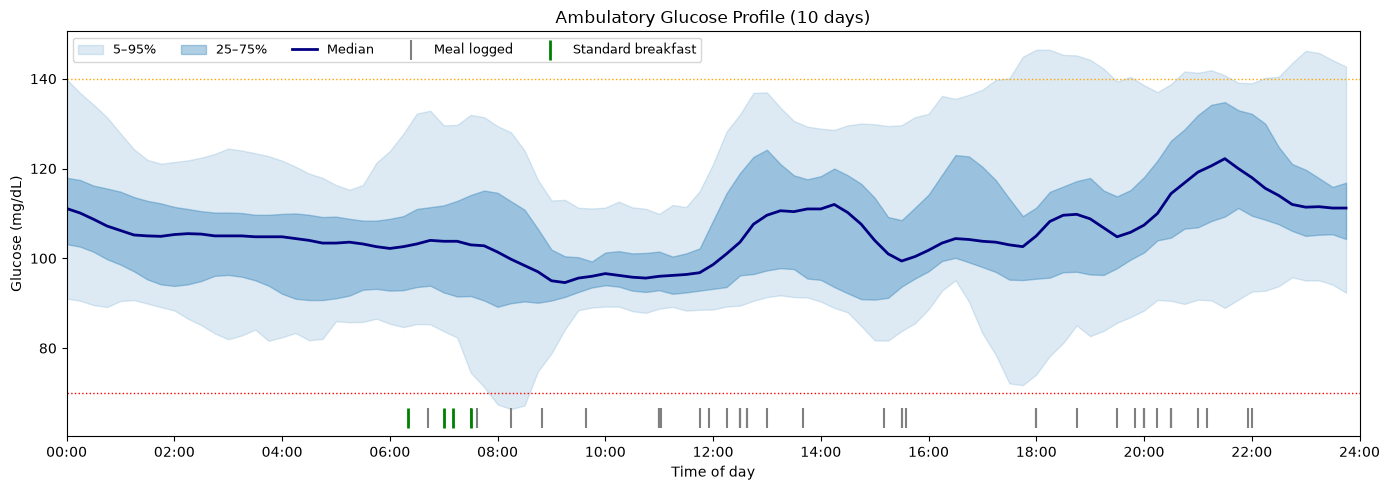

In [11]:
fig, ax = plt.subplots(figsize=(14, 5))
x = agp_smooth.index

ax.fill_between(x, agp_smooth["p5"], agp_smooth["p95"], color="tab:blue", alpha=0.15, label="5–95%")
ax.fill_between(x, agp_smooth["p25"], agp_smooth["p75"], color="tab:blue", alpha=0.35, label="25–75%")
ax.plot(x, agp_smooth["p50"], color="navy", lw=2, label="Median")

ax.axhline(70, color="red", ls=":", lw=1)
ax.axhline(140, color="orange", ls=":", lw=1)

# Meal markers along the bottom
y0 = ax.get_ylim()[0]
other = meals[~meals["standard"]]
std = meals[meals["standard"]]
ax.scatter(other["tod"], [y0 + 2] * len(other), marker="|", s=200, color="gray", label="Meal logged")
ax.scatter(std["tod"], [y0 + 2] * len(std), marker="|", s=200, color="green", lw=2, label="Standard breakfast")

ax.set_xlim(0, 24)
ax.set_xticks(range(0, 25, 2))
ax.set_xticklabels([f"{h:02d}:00" for h in range(0, 25, 2)])
ax.set_xlabel("Time of day")
ax.set_ylabel("Glucose (mg/dL)")
ax.set_title(f"Ambulatory Glucose Profile ({glu['date'].nunique()} days)")
ax.legend(loc="upper left", ncol=5, fontsize=9)
plt.tight_layout()
plt.show()

In [12]:
peak_t, trough_t = agp_smooth["p50"].idxmax(), agp_smooth["p50"].idxmin()
widest_t = (agp_smooth["p75"] - agp_smooth["p25"]).idxmax()

fmt = lambda h: f"{int(h):02d}:{int(round(h % 1 * 60)):02d}"
print(f"Highest median: {agp_smooth['p50'].max():.0f} mg/dL at {fmt(peak_t)}")
print(f"Lowest median:  {agp_smooth['p50'].min():.0f} mg/dL at {fmt(trough_t)}")
print(f"Days differ most (widest 25–75% band) at {fmt(widest_t)}")

Highest median: 122 mg/dL at 21:30
Lowest median:  95 mg/dL at 09:15
Days differ most (widest 25–75% band) at 13:00


---
## Q2: Highest and lowest hours

Here we summarise glucose by clock hour. The median is used because a single spike can pull the mean up. The lower chart shows how many meals were logged in each hour, which usually explains the high hours.

In [13]:
hourly = glu.groupby("hour")["glucose"].agg(
    mean="mean",
    median="median",
    p25=lambda s: s.quantile(0.25),
    p75=lambda s: s.quantile(0.75),
    readings="count",
).round(1)
hourly["meals_logged"] = meals.groupby(meals["time"].dt.hour).size().reindex(hourly.index, fill_value=0)

print("Highest hours (median):")
print(hourly["median"].nlargest(3).to_string())
print("\nLowest hours (median):")
print(hourly["median"].nsmallest(3).to_string())

Highest hours (median):
hour
21    124.0
22    115.0
14    114.0

Lowest hours (median):
hour
9     95.0
10    96.0
11    97.0


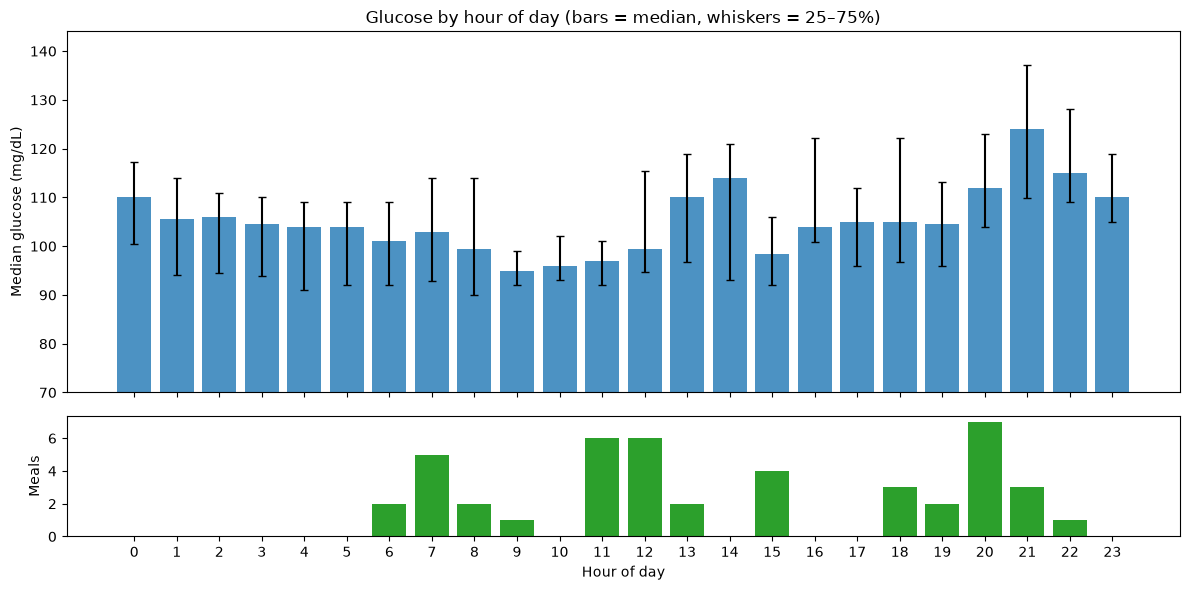

In [14]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})

err = [hourly["median"] - hourly["p25"], hourly["p75"] - hourly["median"]]
axes[0].bar(hourly.index, hourly["median"], yerr=err, capsize=3, color="tab:blue", alpha=0.8)
axes[0].set_ylabel("Median glucose (mg/dL)")
axes[0].set_title("Glucose by hour of day (bars = median, whiskers = 25–75%)")
axes[0].set_ylim(bottom=max(0, hourly["p25"].min() - 20))

axes[1].bar(hourly.index, hourly["meals_logged"], color="tab:green")
axes[1].set_ylabel("Meals")
axes[1].set_xlabel("Hour of day")
axes[1].set_xticks(range(24))
plt.tight_layout()
plt.show()

### Day-by-hour heatmap

Each row is a day and each column an hour. Colours show mean glucose (blue = low, red = high), and black dots mark logged meals. This shows whether a high hour is high **every** day or only on one or two days.

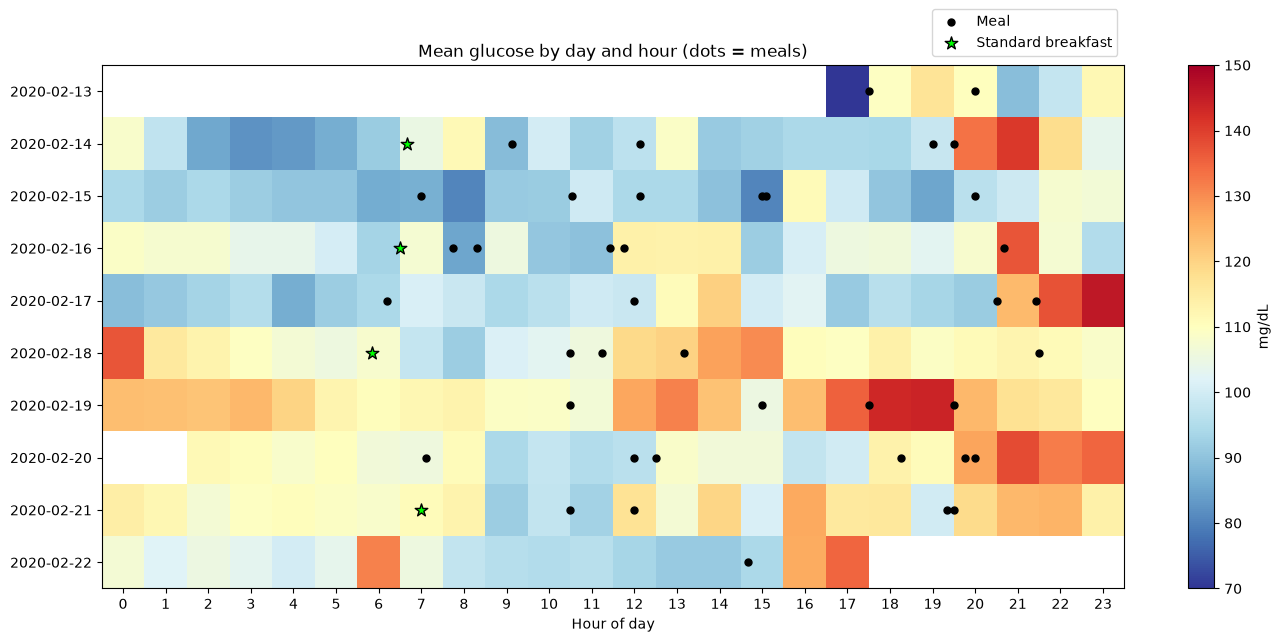

In [15]:
pivot = glu.pivot_table(index="date", columns="hour", values="glucose", aggfunc="mean")
pivot = pivot.reindex(columns=range(24))

fig, ax = plt.subplots(figsize=(14, 0.5 * len(pivot) + 1.5))
im = ax.imshow(pivot, aspect="auto", cmap="RdYlBu_r", vmin=70, vmax=150)

row_of = {d: i for i, d in enumerate(pivot.index)}
m = meals[meals["date"].isin(row_of)]
o = m[~m["standard"]]
ax.scatter(o["tod"] - 0.5, o["date"].map(row_of), color="black", s=25, label="Meal")
s = m[m["standard"]]
ax.scatter(s["tod"] - 0.5, s["date"].map(row_of), color="lime", edgecolor="black", s=90, marker="*",
           label="Standard breakfast")

ax.set_xticks(range(24))
ax.set_yticks(range(len(pivot)))
ax.set_yticklabels([str(d) for d in pivot.index])
ax.set_xlabel("Hour of day")
ax.set_title("Mean glucose by day and hour (dots = meals)")
plt.colorbar(im, ax=ax, label="mg/dL")
ax.legend(loc="upper right", bbox_to_anchor=(1, 1.12))
plt.tight_layout()
plt.show()

---
## Q3: Overnight vs daytime

We split the day into four periods:

| Period | Hours |
|---|---|
| Night | 00:00–06:00 |
| Morning | 06:00–12:00 |
| Afternoon | 12:00–18:00 |
| Evening | 18:00–24:00 |

Night is usually the most stable time, because there is no eating or exercise. It acts as the participant's **baseline**. Late evening meals can keep glucose raised into the early night, so the per-night table also shows when the last meal of the previous evening was.

Remember from Stage 1 that the night of Feb 19–20 has a 3-hour gap.

In [16]:
def period(h):
    if h < 6:
        return "1 Night (00–06)"
    if h < 12:
        return "2 Morning (06–12)"
    if h < 18:
        return "3 Afternoon (12–18)"
    return "4 Evening (18–24)"

glu["period"] = glu["hour"].map(period)

def describe(s):
    return pd.Series({
        "readings": s.count(),
        "mean": s.mean(),
        "median": s.median(),
        "SD": s.std(),
        "CV %": s.std() / s.mean() * 100,
        "min": s.min(),
        "max": s.max(),
        "% 70–140": s.between(70, 140, inclusive="left").mean() * 100,
        "% > 140": (s >= 140).mean() * 100,
    })

by_period = glu.groupby("period")["glucose"].apply(describe).unstack().round(1)
by_period

,readings,mean,median,SD,CV %,min,max,% 70–140,% > 140
period,,,,,,,,,
1 Night (00–06),615.0,104.0,105.0,12.1,11.6,66.0,141.0,99.0,0.7
2 Morning (06–12),647.0,99.9,98.0,13.5,13.5,46.0,143.0,96.9,1.5
3 Afternoon (12–18),655.0,106.9,104.0,16.1,15.1,58.0,155.0,96.5,2.3
4 Evening (18–24),644.0,113.5,111.0,17.5,15.4,59.0,155.0,89.6,10.1


In [17]:
night = glu.loc[glu["hour"] < 6, "glucose"]
day = glu.loc[glu["hour"] >= 6, "glucose"]
nd = pd.DataFrame({"Night (00–06)": describe(night), "Day (06–24)": describe(day)}).round(1)
nd["difference"] = (nd["Day (06–24)"] - nd["Night (00–06)"]).round(1)
nd

,Night (00–06),Day (06–24),difference
readings,615.0,1946.0,1331.0
mean,104.0,106.8,2.8
median,105.0,104.0,-1.0
SD,12.1,16.7,4.6
CV %,11.6,15.7,4.1
min,66.0,46.0,-20.0
max,141.0,155.0,14.0
% 70–140,99.0,94.3,-4.7
% > 140,0.7,4.6,3.9


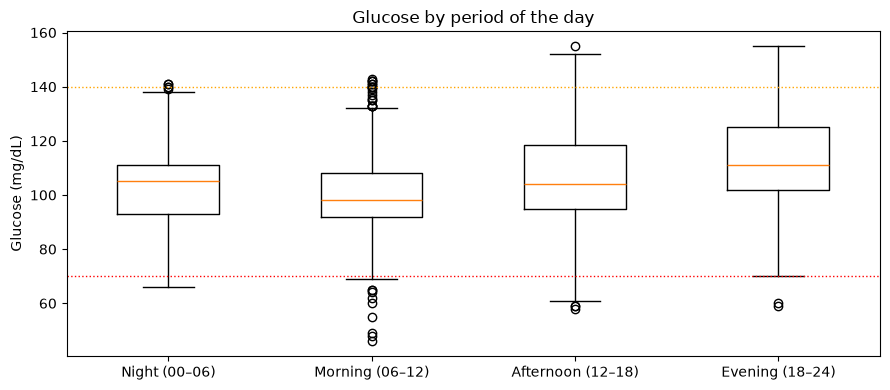

In [18]:
fig, ax = plt.subplots(figsize=(9, 4))
order = sorted(glu["period"].unique())
ax.boxplot([glu.loc[glu["period"] == p, "glucose"] for p in order], widths=0.5)
ax.set_xticks(range(1, len(order) + 1))
ax.set_xticklabels([p[2:] for p in order])
ax.axhline(70, color="red", ls=":", lw=1)
ax.axhline(140, color="orange", ls=":", lw=1)
ax.set_ylabel("Glucose (mg/dL)")
ax.set_title("Glucose by period of the day")
plt.tight_layout()
plt.show()

### Each night separately

A night is marked incomplete if it has fewer than 60 of the 72 possible readings.

In [19]:
nights = glu[glu["hour"] < 6].groupby("date")["glucose"].agg(["count", "mean", "min", "max", "std"]).round(1)
nights["complete"] = nights["count"] >= 60

# Time of the last logged meal on the previous day
last_meal = meals.groupby("date")["time"].max()
nights["last_meal_prev_day"] = [
    last_meal.get(d - timedelta(days=1), pd.NaT) for d in nights.index
]
nights["last_meal_prev_day"] = pd.to_datetime(nights["last_meal_prev_day"]).dt.strftime("%H:%M")
nights

,count,mean,min,max,std,complete,last_meal_prev_day
date,,,,,,,
2020-02-14,72,90.5,66.0,111.0,10.8,True,20:30
2020-02-15,72,92.2,89.0,96.0,1.9,True,20:00
2020-02-16,72,105.4,98.0,110.0,3.4,True,20:30
2020-02-17,72,91.2,83.0,99.0,4.2,True,21:10
2020-02-18,72,114.6,104.0,141.0,10.9,True,21:56
2020-02-19,72,120.8,106.0,126.0,4.8,True,22:00
2020-02-20,39,109.8,105.0,113.0,2.5,False,20:00
2020-02-21,72,110.4,104.0,117.0,3.0,True,20:30
2020-02-22,72,103.6,96.0,117.0,3.3,True,20:00


---
## Q4: Dawn phenomenon

In the early morning the body releases hormones (such as cortisol and growth hormone) that raise glucose before waking. This **dawn phenomenon** shows up as a rise from the lowest point of the night to the value just before breakfast.

For each morning we measure:
- **Nadir:** the lowest glucose between 00:00 and 05:00. Readings are smoothed over 15 min first, so a single compression-low reading doesn't count as the nadir.
- **Pre-breakfast:** the median glucose in the 30 min before the first meal (capped at 09:00, so late breakfasts don't include the whole morning).
- **Dawn rise** = pre-breakfast − nadir.

Studies commonly treat a rise of **20 mg/dL or more** as a clear dawn phenomenon. It is mostly described in people with diabetes, so smaller rises are expected here.

In [20]:
DAWN_THRESHOLD = 20
smooth = glu_s.rolling("15min", center=True).median()

first_meal = meals[meals["time"].dt.hour >= DAY_START_HOUR].groupby("date")["time"].min()

rows = []
for d in sorted(glu["date"].unique()):
    d0 = pd.Timestamp(d)
    night_win = smooth[d0: d0 + pd.Timedelta("5h")]
    if night_win.count() < 36:         # need most of the night (36 of 60 readings)
        continue
    fm = first_meal.get(d, pd.NaT)
    end = min(fm, d0 + pd.Timedelta("9h")) if pd.notna(fm) else d0 + pd.Timedelta("9h")
    pre = glu_s[end - pd.Timedelta(minutes=FASTING_WINDOW_MIN): end - pd.Timedelta("1s")]
    if pre.empty:
        continue
    rows.append({
        "date": d,
        "nadir": night_win.min(),
        "nadir_time": night_win.idxmin().strftime("%H:%M"),
        "first_meal": fm.strftime("%H:%M") if pd.notna(fm) else "none",
        "pre_breakfast": pre.median(),
        "dawn_rise": pre.median() - night_win.min(),
    })

dawn = pd.DataFrame(rows).set_index("date").round(1)
dawn["dawn_present"] = dawn["dawn_rise"] >= DAWN_THRESHOLD
dawn

,nadir,nadir_time,first_meal,pre_breakfast,dawn_rise,dawn_present
date,,,,,,
2020-02-14,68.0,04:23,07:10,95.0,27.0,True
2020-02-15,89.0,04:33,07:30,85.5,-3.5,False
2020-02-16,101.0,03:18,07:00,88.0,-13.0,False
2020-02-17,83.0,04:23,06:42,91.5,8.5,False
2020-02-18,105.0,04:38,06:20,102.5,-2.5,False
2020-02-19,118.0,00:03,11:00,111.0,-7.0,False
2020-02-21,105.0,02:18,07:30,108.0,3.0,False
2020-02-22,97.0,04:18,15:10,94.5,-2.5,False


In [21]:
print(f"Mornings analysed:      {len(dawn)}")
print(f"Mean dawn rise:         {dawn['dawn_rise'].mean():.1f} mg/dL")
print(f"Mornings with rise ≥ {DAWN_THRESHOLD}: {dawn['dawn_present'].sum()} of {len(dawn)}")

Mornings analysed:      8
Mean dawn rise:         1.2 mg/dL
Mornings with rise ≥ 20: 1 of 8


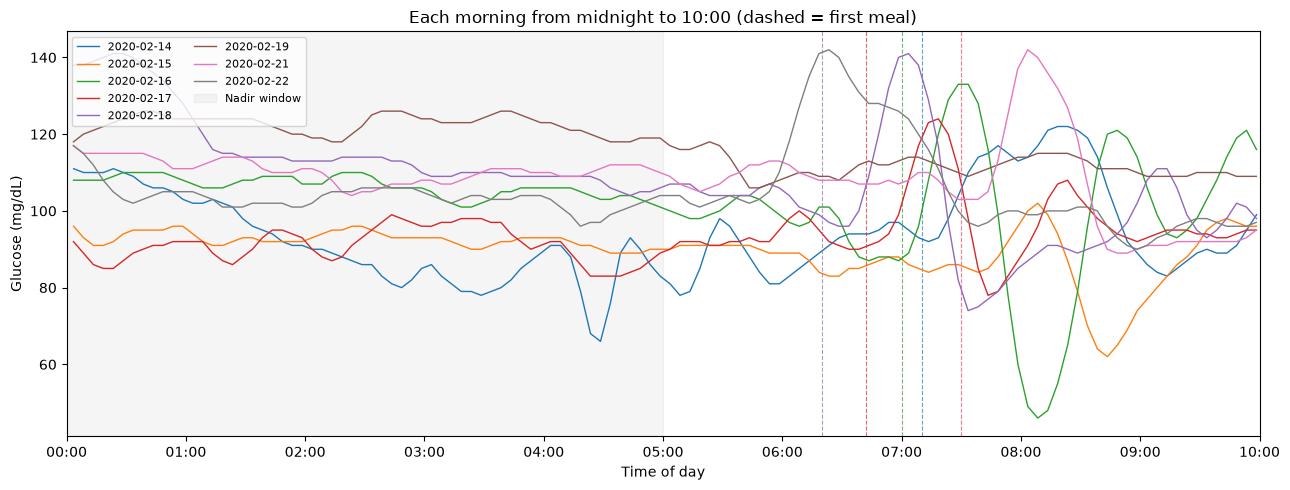

In [22]:
fig, ax = plt.subplots(figsize=(13, 5))
cmap = plt.get_cmap("tab10")

for i, d in enumerate(dawn.index):
    d0 = pd.Timestamp(d)
    trace = glu_s[d0: d0 + pd.Timedelta("10h")]
    hrs = (trace.index - d0).total_seconds() / 3600
    ax.plot(hrs, trace.values, lw=1, color=cmap(i % 10), label=str(d))

    fm = first_meal.get(d, pd.NaT)
    if pd.notna(fm) and fm < d0 + pd.Timedelta("10h"):
        h = (fm - d0).total_seconds() / 3600
        ax.axvline(h, color=cmap(i % 10), ls="--", lw=0.8, alpha=0.7)

ax.axvspan(0, 5, color="gray", alpha=0.08, label="Nadir window")
ax.set_xlim(0, 10)
ax.set_xticks(range(0, 11))
ax.set_xticklabels([f"{h:02d}:00" for h in range(0, 11)])
ax.set_xlabel("Time of day")
ax.set_ylabel("Glucose (mg/dL)")
ax.set_title("Each morning from midnight to 10:00 (dashed = first meal)")
ax.legend(fontsize=8, ncol=2, loc="upper left")
plt.tight_layout()
plt.show()

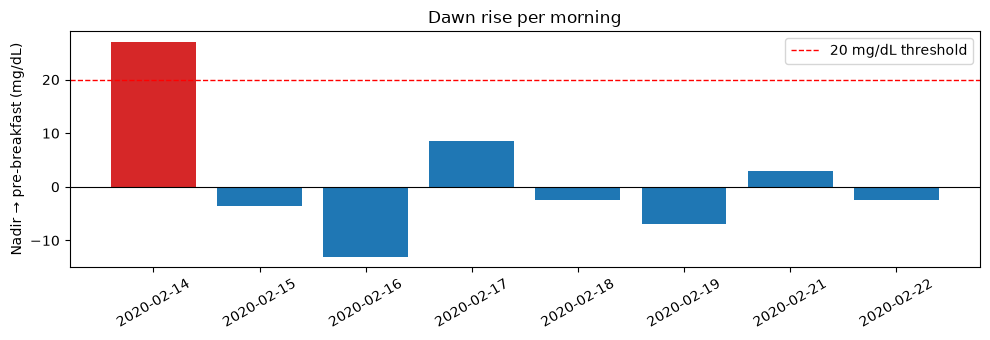

In [23]:
fig, ax = plt.subplots(figsize=(10, 3.5))
colors = np.where(dawn["dawn_present"], "tab:red", "tab:blue")
ax.bar([str(d) for d in dawn.index], dawn["dawn_rise"], color=colors)
ax.axhline(DAWN_THRESHOLD, color="red", ls="--", lw=1, label=f"{DAWN_THRESHOLD} mg/dL threshold")
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("Nadir → pre-breakfast (mg/dL)")
ax.set_title("Dawn rise per morning")
ax.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

---
## Q5: Fasting glucose each morning

The fasting glucose is the median of the readings in the 30 minutes **before the first meal of the day** (the first meal after 04:00).

Some days need care:
- **Partial days:** if the recording doesn't cover the morning, there is no fasting value.
- **Late first meal:** if the first logged meal is after 10:00, breakfast may simply not have been logged, so the value may not be truly fasting.
- **Standard breakfast days** are marked, because those mornings are the most comparable.

For reference, a lab fasting glucose below 100 mg/dL is normal and 100–125 mg/dL is in the prediabetes range. These cut-offs are for blood tests, so CGM values are only a rough guide.

In [24]:
rows = []
for d in sorted(glu["date"].unique()):
    fm = first_meal.get(d, pd.NaT)
    if pd.isna(fm):
        rows.append({"date": d, "first_meal": "none logged", "note": "no meal logged"})
        continue

    win = glu_s[fm - pd.Timedelta(minutes=FASTING_WINDOW_MIN): fm - pd.Timedelta("1s")]
    meal = meals[meals["time"] == fm].iloc[0]

    notes = []
    if glu.loc[glu["date"] == d, "timestamp"].min() > pd.Timestamp(d) + pd.Timedelta("6h"):
        notes.append("recording starts after the morning")
    if len(win) < 4:
        notes.append("not enough readings before meal")
    if fm.hour >= 10:
        notes.append("late first meal, check for unlogged breakfast")

    rows.append({
        "date": d,
        "first_meal": fm.strftime("%H:%M"),
        "foods": meal["foods"][:45],
        "standard": meal["standard"],
        "fasting": win.median() if len(win) >= 4 else np.nan,
        "readings": len(win),
        "note": "; ".join(notes),
    })

fasting = pd.DataFrame(rows).set_index("date")
fasting["fasting"] = fasting["fasting"].round(1)
fasting

,first_meal,foods,standard,fasting,readings,note
date,,,,,,
2020-02-13,18:00,Berry Smoothie,False,63.0,6,recording starts after the morning; late first...
2020-02-14,07:10,"Natrel Lactose Free 2 Percent, Standard Break",True,95.0,6,
2020-02-15,07:30,Spinach Smoothie,False,85.5,6,
2020-02-16,07:00,"Natrel Lactose Free 2 Percent, Standard Break",True,88.0,6,
2020-02-17,06:42,Maple Brown Sugar Oatmeal,False,91.5,6,
2020-02-18,06:20,"Natrel Lactose Free 2 Percent, Standard Break",True,102.5,6,
2020-02-19,11:00,Acai Smoothie,False,108.5,6,"late first meal, check for unlogged breakfast"
2020-02-20,07:37,"Bagel, Green Smoothie",False,100.0,6,
2020-02-21,07:30,"Natrel Lactose Free 2 Percent, Standard Break",True,108.0,6,


In [25]:
valid = fasting.dropna(subset=["fasting"])
reliable = valid[valid["note"] == ""]

print(f"Mean fasting glucose (all valid days):   {valid['fasting'].mean():.1f} mg/dL  (n = {len(valid)})")
print(f"Mean fasting glucose (reliable days):    {reliable['fasting'].mean():.1f} mg/dL  (n = {len(reliable)})")
print(f"Range: {valid['fasting'].min():.0f} – {valid['fasting'].max():.0f} mg/dL")
print(f"Days ≥ 100 mg/dL: {(valid['fasting'] >= 100).sum()} of {len(valid)}")

if valid["standard"].any():
    print(f"\nStandard breakfast days: {valid.loc[valid['standard'] == True, 'fasting'].mean():.1f} mg/dL")
    print(f"Other days:              {valid.loc[valid['standard'] != True, 'fasting'].mean():.1f} mg/dL")

Mean fasting glucose (all valid days):   93.2 mg/dL  (n = 10)
Mean fasting glucose (reliable days):    95.8 mg/dL  (n = 7)
Range: 63 – 108 mg/dL
Days ≥ 100 mg/dL: 4 of 10

Standard breakfast days: 98.4 mg/dL
Other days:              89.7 mg/dL


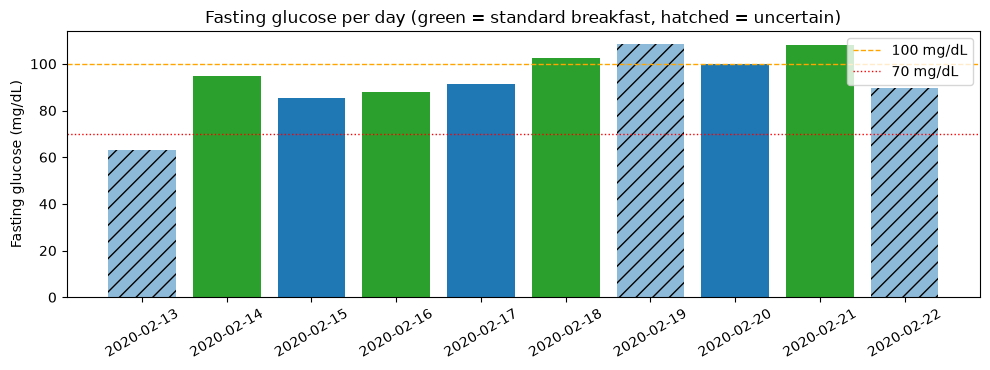

In [26]:
fig, ax = plt.subplots(figsize=(10, 3.8))
colors = ["tab:green" if s == True else "tab:blue" for s in valid["standard"]]
bars = ax.bar([str(d) for d in valid.index], valid["fasting"], color=colors)
for bar, note in zip(bars, valid["note"]):
    if note:
        bar.set_hatch("//")
        bar.set_alpha(0.5)

ax.axhline(100, color="orange", ls="--", lw=1, label="100 mg/dL")
ax.axhline(70, color="red", ls=":", lw=1, label="70 mg/dL")
ax.set_ylabel("Fasting glucose (mg/dL)")
ax.set_title("Fasting glucose per day (green = standard breakfast, hatched = uncertain)")
ax.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

---
## Summary

All Stage 4 answers in one table. The cleaned meal table and the per-morning results are saved too, because Stage 6 (meal responses) will reuse them.

In [27]:
summary = pd.Series({
    "AGP highest median (mg/dL)": round(agp_smooth["p50"].max(), 1),
    "AGP highest median at": fmt(peak_t),
    "AGP lowest median (mg/dL)": round(agp_smooth["p50"].min(), 1),
    "AGP lowest median at": fmt(trough_t),
    "Highest hour (median)": int(hourly["median"].idxmax()),
    "Lowest hour (median)": int(hourly["median"].idxmin()),
    "Night mean 00–06 (mg/dL)": round(night.mean(), 1),
    "Day mean 06–24 (mg/dL)": round(day.mean(), 1),
    "Night CV (%)": round(night.std() / night.mean() * 100, 1),
    "Day CV (%)": round(day.std() / day.mean() * 100, 1),
    "Mean dawn rise (mg/dL)": round(dawn["dawn_rise"].mean(), 1),
    f"Mornings with dawn rise ≥ {DAWN_THRESHOLD}": f"{dawn['dawn_present'].sum()} of {len(dawn)}",
    "Mean fasting glucose (mg/dL)": round(valid["fasting"].mean(), 1),
    "Fasting range (mg/dL)": f"{valid['fasting'].min():.0f}–{valid['fasting'].max():.0f}",
    "First 24 h excluded": EXCLUDE_FIRST_24H,
}, name=PID)

summary.to_frame()

,001
AGP highest median (mg/dL),122.2
AGP highest median at,21:30
AGP lowest median (mg/dL),94.6
AGP lowest median at,09:15
Highest hour (median),21
Lowest hour (median),9
Night mean 00–06 (mg/dL),104.0
Day mean 06–24 (mg/dL),106.8
Night CV (%),11.6
Day CV (%),15.7


In [28]:
summary.to_frame().T.rename_axis("participant").to_csv(f"../clean_data/stage4_summary_{PID}.csv")
meals.to_csv(f"../clean_data/meals_{PID}.csv", index=False)
dawn.join(fasting[["first_meal", "fasting", "standard", "note"]], how="outer", rsuffix="_f") \
    .to_csv(f"../clean_data/stage4_mornings_{PID}.csv")
print(f"Saved stage4_summary_{PID}.csv, meals_{PID}.csv, stage4_mornings_{PID}.csv")

Saved stage4_summary_001.csv, meals_001.csv, stage4_mornings_001.csv
